### Encoded MI estimation with CrossInfoGAN

In [17]:
import torch
from torchvision import datasets, transforms
from models.nn import *
import matplotlib.pyplot as plt
from models.utils import *

In [18]:
# set the random seed
torch.manual_seed(0)
np.random.seed(0)

In [19]:
loss_fn = 'DV_loss' # NWJ_loss ; DV_loss ; NCE_loss; PCM_loss
miest_type = 'all' # 'l1'
img_size = 32
reg = True
refbatch = True

In [ ]:
# load the data
transform = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# load mnist
train_dataset = datasets.MNIST('../data/', train=True, download=True, transform=transform)


In [21]:
test_labels = 10
n_classes = 10

In [22]:
grouped_data = {label: [] for label in range(10)}
train_loaders = []

# group the data
for data in train_dataset:
    label = data[1]
    grouped_data[label].append(data)

class_batch_size = 100
for c in range(test_labels):
    train_loaders.append(torch.utils.data.DataLoader(grouped_data[c], batch_size=class_batch_size, shuffle=True))

# construct the train dataset: X, Y are i.i.d. samples from the same class
X = []
Y = []
for c in range(test_labels):
    # for _ in range(10):
    data1, _ = next(iter(train_loaders[c]))
    data2, _ = next(iter(train_loaders[c]))
    X.append(data1)
    Y.append(data2)

X = torch.cat(X)
Y = torch.cat(Y)
XY = torch.cat((X, Y), dim=1)

In [23]:
from models.KSG import KSG, Mixed_KSG

In [24]:
import scipy.spatial as ss
from scipy.special import digamma
from math import log

def KSG(x,y,k=5,dist_type=2):
	assert len(x)==len(y), "Lists should have same length"
	assert k <= len(x)-1, "Set k smaller than num. samples - 1"
	N = len(x)
	if x.ndim == 1:
		x = x.reshape((N,1))
	dx = len(x[0])
	if y.ndim == 1:
		y = y.reshape((N,1))
	dy = len(y[0])
	data = np.concatenate((x,y),axis=1)

	tree_xy = ss.cKDTree(data)
	tree_x = ss.cKDTree(x)
	tree_y = ss.cKDTree(y)

	knn_dis = [tree_xy.query(point,k+1,p=dist_type)[0][k] for point in data]
	ans = 0

	# for i in range(N):
	# 	nx = len(tree_x.query_ball_point(x[i],knn_dis[i]-1e-15,p=dist_type))+1
	# 	ny = len(tree_y.query_ball_point(y[i],knn_dis[i]-1e-15,p=dist_type))+1
	# 	ans += (digamma(k) + log(N) - digamma(nx) - digamma(ny))/N
	for i in range(N):
		nx = len(tree_x.query_ball_point(x[i],knn_dis[i],p=dist_type))
		ny = len(tree_y.query_ball_point(y[i],knn_dis[i],p=dist_type))
		ans += (digamma(k) + log(N) - digamma(nx) - digamma(ny) - 1/k)/N
	return ans

In [25]:
# Geodesic KSG
from sklearn.manifold import LocallyLinearEmbedding, Isomap

emb = Isomap(n_components=20, n_neighbors=10)
X_emb = emb.fit_transform(X.reshape(X.shape[0], -1).numpy())
Y_emb = emb.fit_transform(Y.reshape(Y.shape[0], -1).numpy())
KSG(X_emb, Y_emb, k=10, dist_type=float('inf'))

1.1116415015175407

In [26]:
KSG(X.reshape(X.shape[0], -1).numpy(), Y.reshape(Y.shape[0], -1).numpy(), k=10, dist_type=float('inf'))

-1.4760192196259894

In [ ]:
# move to GPU
net = DNN_Net(input_size=(n_classes+2)*2)
discriminator = Discriminator(img_size=img_size, code_dim=2)
optimizer = torch.optim.Adam(net.parameters(), lr=0.0002, betas=(0.5, 0.999))

if torch.cuda.is_available():
    X = X.cuda()
    Y = Y.cuda()
    XY = XY.cuda()
    discriminator.cuda()
    net.cuda()

# load the discriminator
discriminator.load_state_dict(torch.load('checkpoints/cont2dist10discriminator_199.pt'))

<All keys matched successfully>

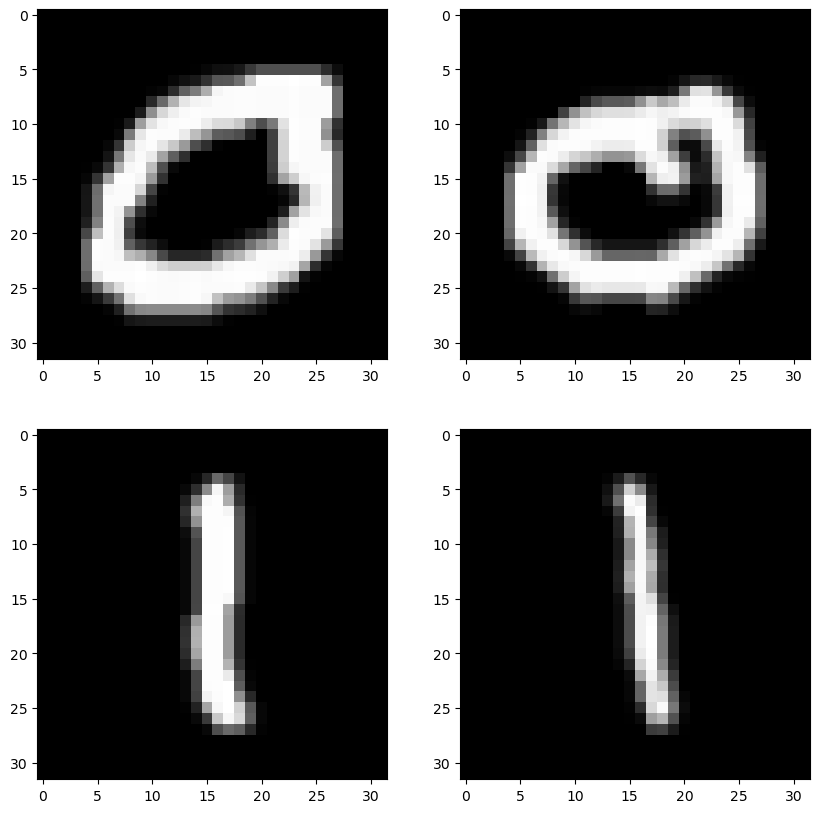

In [28]:
# plot the mnist data X, Y
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plt.imshow(X[0][0].cpu().detach().numpy(), cmap='gray')
plt.subplot(2, 2, 2)
plt.imshow(Y[0][0].cpu().detach().numpy(), cmap='gray')
plt.subplot(2, 2, 3)
plt.imshow(X[100][0].cpu().detach().numpy(), cmap='gray')
plt.subplot(2, 2, 4)
plt.imshow(Y[100][0].cpu().detach().numpy(), cmap='gray')
plt.show()


In [ ]:
def code(encoder, data, type='dis'):
    """Obtain the codes from the pixel data.count

    Args:
        - encoder: the encoder of InfoGAN model Q(c|X)
        - data: pixel data

    Return:
        The codes/representation of data.
    """
    _, label, latent_code = encoder(data)
    dis_code = torch.argmax(label, dim=1)
    if type == 'dis':
        return F.one_hot(dis_code.long(), num_classes=n_classes).float()
    elif type == 'con':
        return latent_code
    elif type == 'all':
        return torch.cat((latent_code, F.one_hot(dis_code.long(), num_classes=n_classes).float()), dim=1)
    elif type == 'digit':
        return dis_code
    elif type == 'cont_all':
        return torch.cat((F.sigmoid(latent_code), F.softmax(label)), dim=1)

def DV_loss(D, x, y, y_ref=None, reg=False, alpha=1.0):
    '''
    D: discriminator
    x: data x
    y: data y
    '''
    # reshuffle y and concatenate with x
    joint_xy = torch.cat((x, y), dim=1)
    # if y_ref is None:
    #     marginal_xy = torch.cat((x, y[torch.randperm(x.size()[0])]), dim=1)
    # else:
    #     marginal_xy = torch.cat((x, y_ref[torch.randperm(x.size()[0])]), dim=1)
    if y_ref is None:
        x_tile = x.unsqueeze(0).repeat((y.shape[0], 1, 1))
        y_tile = y.unsqueeze(1).repeat((1, x.shape[0], 1))
        marginal_xy = torch.cat((x_tile, y_tile), dim=-1).view(x.shape[0]*y.shape[0], -1)
    else:
        x_tile = x.unsqueeze(0).repeat((y_ref.shape[0], 1, 1))
        y_tile = y_ref.unsqueeze(1).repeat((1, x.shape[0], 1))
        marginal_xy = torch.cat((x_tile, y_tile), dim=-1).view(x.shape[0]*y_ref.shape[0], -1)

    # joint_xy = x + y
    # marginal_xy = x + y[torch.randperm(x.size()[0])]
    if reg:
        return -D(joint_xy.view(joint_xy.size(0), -1)).mean() + torch.logsumexp(D(marginal_xy.view(marginal_xy.size(0), -1)), dim=0).mean() - np.log(marginal_xy.shape[0]) + alpha*(torch.logsumexp(D(marginal_xy.view(marginal_xy.size(0), -1)), dim=0).mean() - np.log(marginal_xy.shape[0]))**2
    else:
        return - D(joint_xy.view(joint_xy.size(0), -1)).mean() + torch.logsumexp(D(marginal_xy.view(marginal_xy.size(0), -1)), dim=0).mean() - np.log(marginal_xy.shape[0])

In [11]:
digit_x = code(discriminator, X, type='digit').reshape(-1,1)
digit_y = code(discriminator, Y, type='digit').reshape(-1,1)
digit_xy = torch.cat((digit_x,digit_y), dim=1)

/home/wangxu/anaconda3/envs/torch/lib/python3.7/site-packages/torch/nn/modules/container.py:204: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  input = module(input)


In [12]:
def entropy(p):
    entropy = - p * np.log(p)
    entropy[np.isnan(entropy)] = 0
    return entropy.sum()

from collections import Counter
p_codex= np.array(list(Counter(digit_x.squeeze(dim=1).cpu().detach().numpy()).values()))/len(X)
p_codey= np.array(list(Counter(digit_y.squeeze(dim=1).cpu().detach().numpy()).values()))/len(Y)
p_codexy = np.array(list(Counter([tuple(x) for x in digit_xy.cpu().detach().numpy()]).values()))/len(XY)

emp_mi = entropy(p_codex)+entropy(p_codey)-entropy(p_codexy)
entropy(p_codex), entropy(p_codey), entropy(p_codexy), entropy(p_codex)+entropy(p_codey)-entropy(p_codexy)

(2.302149877529389, 2.301813650631841, 2.7715233926115164, 1.8324401355497142)

In [13]:
max_iter = 40000
batch_size = 20
ref_batch_size = batch_size
mi_list = []
with torch.no_grad():
    code_X = code(discriminator, X, type='all')
    code_Y = code(discriminator, Y, type='all')
# dis_mi = mutual_information(dis_codeX.cpu(), dis_codeY.cpu())

for i in range(max_iter):
    # draw mini-batch data
    idx = resample(X, batch_size, return_idx=True)

    # train
    optimizer.zero_grad()

    # dis_mi = mutual_information(dis_codex.cpu(), dis_codey.cpu())
    if refbatch:
        idx_ref = resample(Y, ref_batch_size, return_idx=True)
        # batch_codex = code(discriminator, X[idx])
        # batch_codey = code(discriminator, Y[idx])
        # refbatch_codey = code(discriminator, Y[idx_ref])
        batch_codex = code_X[idx]
        batch_codey = code_Y[idx]
        refbatch_codey = code_Y[idx_ref]
        loss = eval(loss_fn)(net, batch_codex, batch_codey, refbatch_codey, reg=reg)
    else:
        loss = eval(loss_fn)(net, batch_codex, batch_codey, reg=reg)
    loss.backward()

    # torch.nn.utils.clip_grad_norm_(net.parameters(), 0.02)
    optimizer.step()
    with torch.no_grad():
        if miest_type == 'all':
            mi_list.append(-eval(loss_fn)(net, code_X, code_Y).item())
        elif miest_type == 'l1':
            mi_list.append(mi_estimate(net, torch.cat((code_X, code_Y), dim=1)).item())
    if i % 200 == 0:
        print('iter: {}, mi estimation: {}'.format(i, mi_list[-1]))

iter: 0, mi estimation: -1.9073486328125e-06


iter: 200, mi estimation: 0.00020503997802734375
iter: 400, mi estimation: 0.0016565322875976562
iter: 600, mi estimation: 0.008641242980957031
iter: 800, mi estimation: 0.04045677185058594
iter: 1000, mi estimation: 0.2098093032836914
iter: 1200, mi estimation: 0.7092714309692383
iter: 1400, mi estimation: 1.2305631637573242
iter: 1600, mi estimation: 1.4924726486206055
iter: 1800, mi estimation: 1.557363510131836
iter: 2000, mi estimation: 1.6630268096923828
iter: 2200, mi estimation: 1.6682538986206055
iter: 2400, mi estimation: 1.7015933990478516
iter: 2600, mi estimation: 1.7262992858886719
iter: 2800, mi estimation: 1.7232551574707031
iter: 3000, mi estimation: 1.7405176162719727
iter: 3200, mi estimation: 1.74432373046875
iter: 3400, mi estimation: 1.7483901977539062
iter: 3600, mi estimation: 1.7406415939331055
iter: 3800, mi estimation: 1.7282981872558594
iter: 4000, mi estimation: 1.7385501861572266
iter: 4200, mi estimation: 1.746964454650879
iter: 4400, mi estimation: 1.742

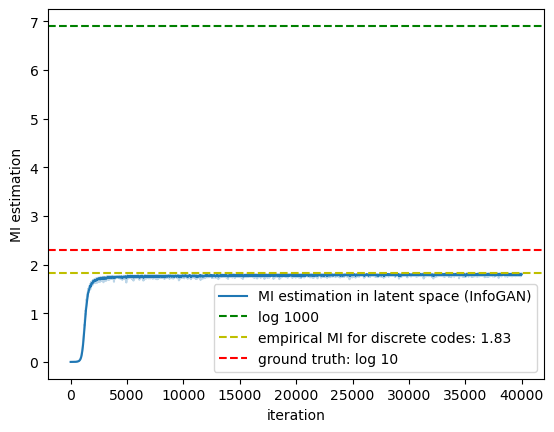

The figure is saved at ./figs/InfoGAN_miall_label10bs20regTruerefTrue.png


In [14]:
import pandas as pd
import math

EMA_SPAN = 50
p1 = plt.plot(mi_list, alpha=0.3)[0]
mis_smooth = pd.Series(mi_list).ewm(span=EMA_SPAN).mean()
plt.plot(mis_smooth, c=p1.get_color(), label='MI estimation in latent space (InfoGAN)')
plt.axhline(math.log(XY.shape[0]), c='g', ls='--', label=f'log {XY.shape[0]}')
plt.axhline(emp_mi, c='y', ls='--', label=f'empirical MI for discrete codes: {emp_mi:.2f}')
# plt.axhline(math.log(batch_size), ls='--', label=f'log {batch_size}')
# plt.ylim(0, 2*math.log(batch_size))
plt.axhline(math.log(test_labels), c='r', ls='--', label=f'ground truth: log {test_labels}')
plt.xlabel('iteration')
plt.ylabel('MI estimation')
plt.legend()
# plt.title(f'labels:{test_labels} {loss_fn}')
# plt.legend(['raw', 'MI EMA', ])
plt.savefig(f'./figs/one_hotInfoGAN_mi{miest_type}_label{test_labels}bs{batch_size}reg{reg}ref{refbatch}.pdf')
plt.show()
print(f'The figure is saved at ./figs/InfoGAN_mi{miest_type}_label{test_labels}bs{batch_size}reg{reg}ref{refbatch}.png')

In [12]:
chkpt_name = './checkpoints/latent_DV.pt'
overwrite = True  # set to True to overwrite previously stored results
if overwrite or not os.path.exists(chkpt_name):
    torch.save({
        'mi_list': mi_list,
        'net_state_list': net.state_dict(),
        'optimizer_state_list': optimizer.state_dict(),
    }, chkpt_name)
    print('Current results saved.')

Current results saved.
